# **"EcoHome": Real Estate Price Predictor**

### **The Scenario**
You have been hired as a Data Scientist for **"EcoHome,"** a tech-enabled real estate firm. Your company wants to automate the valuation of properties to give sellers an instant price estimate.

Instead of sending an appraiser to every house, you must build an algorithm that predicts the **Price ($y$)** of a house based on its **Living Area ($x_1$)** and **Age ($x_2$)**.

Your task is to implement and analyze **Linear Regression** models to solve this problem. You will explore two main approaches discussed in Lecture 3: the **Closed Form Solution** and **Gradient Descent**.

---

### **Part 1: The Hypothesis & Loss Function**

We assume the relationship between features ($x$) and price ($y$) is linear. For a single house $i$, the predicted price $\hat{y}_i$ is:
$$\hat{y}_i = w_1 x_{i,1} + w_2 x_{i,2} + w_0$$
where $w_0$ is the bias (intercept).

To evaluate our model, we use the **Mean Squared Error (MSE)** loss function, which penalizes large errors:
$$J(w) = \frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2$$

### **Knowledge Check: The "Castle" Problem**

**Question 1:**
You are training your model on a dataset that includes standard suburban homes and exactly **one** massive historic castle.
* **Standard Homes:** ~2,000 sq ft, sold for \$300k - \$500k.
* **The Castle (Outlier):** 50,000 sq ft, sold for \$50,000,000.

If you train a standard Linear Regression model using **Squared Error Loss** on this data, what is the most likely geometric outcome for your regression line?

A) The line will fit the standard homes perfectly and treat the castle as noise (ignore it).

**B) The line will be pulled significantly upward toward the Castle, likely causing it to overestimate the price of every normal house.**

C) The line will break and return an error because the loss function is non-convex.

D) The line will curve to hit all points exactly.

B, The line will be pulled becuase linear regression tries to minimize the error of all samples.

### **Part 2: The Closed Form Solution**

For datasets that fit in memory, we can solve for the optimal weights $w^*$ in a single step using the **Normal Equation** derived in class:
$$w^* = (X^T X)^{-1} X^T Y$$

### **Critical Thinking: Matrix Invertibility**

**Question 2:**
Imagine your intern hands you a dataset with a mistake. They included the "Size" feature twice, but in different units:
* Feature 1: Size in **Square Feet**.
* Feature 2: Size in **Square Meters** (where $1 \text{ sq m} \approx 10.76 \text{ sq ft}$).

If you attempt to calculate the Closed Form Solution $w^* = (X^T X)^{-1} X^T Y$ with both features included, what will happen?

A) The model will become twice as accurate.

***B) The matrix $X^T X$ will be **singular (non-invertible)** because the columns are linearly dependent, causing the calculation to crash or be unstable.***

C) The model will automatically delete one of the columns.

D) The eigenvalues of $X^T X$ will all become 1.

The XTX will be singular if the columns of X are linearly dependent. which actually makes matrix non invertible, but the libraries give a numerical noise which causes calculation errors and crashes.

In [44]:
import torch

x = torch.tensor([[1, 2, 3, 4, 5], [6, 7, 8, 9, 10], [2, 4, 6, 8, 10]])
y = torch.tensor([1, 0, 1, 0, 1])

print(x)
print(y)

tensor([[ 1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10],
        [ 2,  4,  6,  8, 10]])
tensor([1, 0, 1, 0, 1])


In [45]:
x1 = (x.T).matmul(x)
x1

tensor([[ 41,  52,  63,  74,  85],
        [ 52,  69,  86, 103, 120],
        [ 63,  86, 109, 132, 155],
        [ 74, 103, 132, 161, 190],
        [ 85, 120, 155, 190, 225]])

In [46]:
x1 = x1.float()
x1.det() # this is o.00000... numerical result actually something which is unstable

tensor(-1.1404e-24)

In [47]:
# Convert x1 to a float tensor
x1 = x1.float()

# Inverse x1 using torch
x1_inv = torch.inverse(x1)


In [48]:
x1_inv

tensor([[-3.4954e+05,  1.1141e+06, -8.1920e+05,  1.3982e+06, -3.0000e+01],
        [ 2.0753e+05,  4.4564e+06, -7.4711e+06,  1.3981e+06,  2.6214e+06],
        [ 2.3456e+13,  9.1750e+07, -1.2137e+08, -9.3825e+13,  7.0369e+13],
        [-4.6912e+13, -2.0133e+08,  2.6844e+08,  1.8765e+14, -1.4074e+14],
        [ 2.3456e+13,  1.0401e+08, -1.3877e+08, -9.3825e+13,  7.0369e+13]])

### **Part 3: Weighted Linear Regression**

"EcoHome" discovers that some data sources are more reliable than others.
* **Govt Records:** 100% Reliable ($\alpha_i = 1.0$)
* **User Surveys:** Less Reliable ($\alpha_i = 0.5$)

We modify our loss function to weight the squared error of each sample by its confidence score $\alpha_i$:
$$\mathcal{L} = \frac{1}{N} \sum_{i=1}^{N} \alpha_i (y_i - \hat{y}_i)^2$$

### **Derivation Challenge**

**Question 3:**
We need to update our Gradient Descent rule for this new loss.
Recall the standard chain rule: $\frac{\partial}{\partial w} (y - \hat{y})^2 = 2(y - \hat{y})(-x)$.

Which of the following represents the correct **Gradient Descent Update Rule** for weights $w$ (with learning rate $\eta$)?

A) $w \leftarrow w - \eta \frac{2}{N} \sum_{i=1}^N (y_i - \hat{y}_i) x_i$  *(The $\alpha$ cancels out)*

***B) $w \leftarrow w + \eta \frac{2}{N} \sum_{i=1}^N \alpha_i (y_i - \hat{y}_i) x_i$***

C) $w \leftarrow w - \eta \frac{2}{N} \sum_{i=1}^N \frac{1}{\alpha_i} (y_i - \hat{y}_i) x_i$

D) $w \leftarrow w - \eta \sum_{i=1}^N \alpha_i^2 (y_i - \hat{y}_i)$

***B) $w \leftarrow w + \eta \frac{2}{N} \sum_{i=1}^N \alpha_i (y_i - \hat{y}_i) x_i$***
becuase alpha as a constant cmes out of the sum and the gradient is with respect to w

### **Part 4: Linear Algebra & Optimization Properties**

Consider the matrix $A = X^T X$.

**Question 4:**
When we solve for the minimum of the loss function, we essentially set the gradient to zero. To ensure that the critical point we find is a **Global Minimum** (the bottom of a bowl) rather than a Maximum (top of a hill) or Saddle Point, what property must the matrix $X^T X$ (the Hessian of the loss) satisfy?

A) It must be an Orthogonal Matrix ($A^T = A^{-1}$).

**B) It must be Positive Semi-Definite (PSD) ($z^T A z \geq 0$).**

C) It must be a Diagonal Matrix.

D) It must have a determinant of 0.

It must be positive semi definite

### **Part 5: Coding Challenge - Gradient Descent vs Closed Form**

**Task:**
### **Part 5: Coding Challenge - Gradient Descent vs Closed Form**

**Task:**
1.  Implement the `closed_form_solution` function using `numpy`. (Only add the missing line(s) of code)
2.  Implement the `gradient_descent` function. (Only add the missing line(s) of code)
3.  Compare the results on the generated "EcoHome" data.

In [49]:
import numpy as np
import matplotlib.pyplot as plt

In [50]:
# 1. Generate Synthetic Data
np.random.seed(42)
N = 100
# Feature: Size (sq ft) centered/scaled
X_size = 2 * np.random.rand(N, 1)
# True Relation: Price = 4 + 3 * Size + Noise
y = 4 + 3 * X_size + np.random.randn(N, 1)

# Add Bias Term (Column of 1s) to X
X_b = np.c_[np.ones((N, 1)), X_size]

In [51]:
X_size.shape, y.shape, X_b.shape

((100, 1), (100, 1), (100, 2))

In [52]:
# --- STUDENT IMPLEMENTATION 1: CLOSED FORM ---
def closed_form_solution(X, y):
    """
    Compute w* in closed form.
    """
    # TODO: Implement the Normal Equation
    w_best = np.linalg.inv(X.T @ X) @ X.T @ y

    return w_best

In [53]:
# --- STUDENT IMPLEMENTATION 2: GRADIENT DESCENT ---
def gradient_descent(X, y, learning_rate=0.1, n_iterations=1000):
    m = len(X)
    w = np.random.randn(2, 1) # Random initialization
    # print(m,w)

    for iteration in range(n_iterations):
        # TODO: Calculate Gradients
        gradients = (1 / m) * X.T @ (X @ w - y)
        # print(gradients)


        w = w - learning_rate * gradients
        # print(w)


    return w

In [54]:
# Run and Compare
w_closed = closed_form_solution(X_b, y)
w_gd = gradient_descent(X_b, y, learning_rate=0.5)

In [55]:
print(f"Closed Form Solution Weights: Intercept={w_closed[0][0]:.4f}, Slope={w_closed[1][0]:.4f}")
print(f"Gradient Descent Weights:     Intercept={w_gd[0][0]:.4f}, Slope={w_gd[1][0]:.4f}")

Closed Form Solution Weights: Intercept=4.2151, Slope=2.7701
Gradient Descent Weights:     Intercept=4.2151, Slope=2.7701


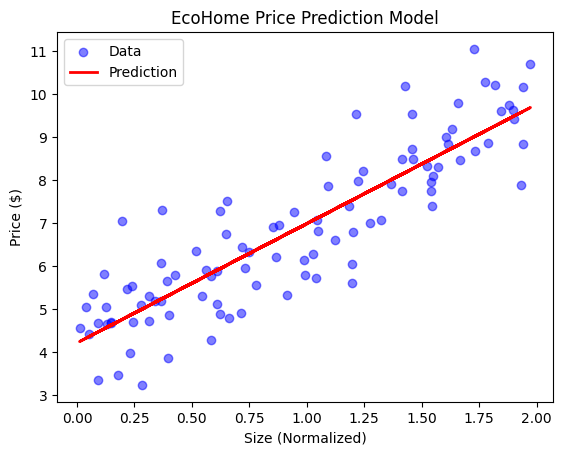

In [56]:
# Plotting Closed Form Solution
plt.scatter(X_size, y, color='blue', alpha=0.5, label='Data')
plt.plot(X_size, X_b.dot(w_closed), color='red', linewidth=2, label='Prediction')
plt.legend()
plt.title("EcoHome Price Prediction Model")
plt.xlabel("Size (Normalized)")
plt.ylabel("Price ($)")
plt.show()

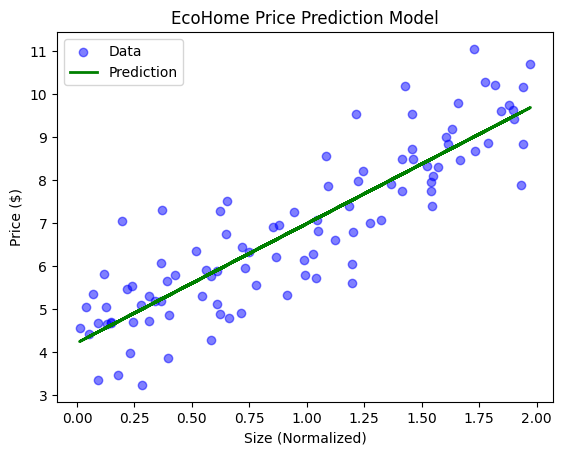

In [57]:
# Plotting Gradient Descent Solution
plt.scatter(X_size, y, color='blue', alpha=0.5, label='Data')
plt.plot(X_size, X_b.dot(w_gd), color='green', linewidth=2, label='Prediction')
plt.legend()
plt.title("EcoHome Price Prediction Model")
plt.xlabel("Size (Normalized)")
plt.ylabel("Price ($)")
plt.show()

### **Interactive Challenge: The "Exploding" Gradient**

**Task:**
In the `gradient_descent` function call above, change `learning_rate=0.1` to `learning_rate=0.5`.
Run the code again.

**Question 5:** What happens to the weights and the prediction line? Why?

It just took more steps/iterations to get to the line, but the answer was same with o.5 learning rate as well

# **Bonus Question**

**Task:**
Modify the gradient descent code such that you can visualize the prediction line after every update.

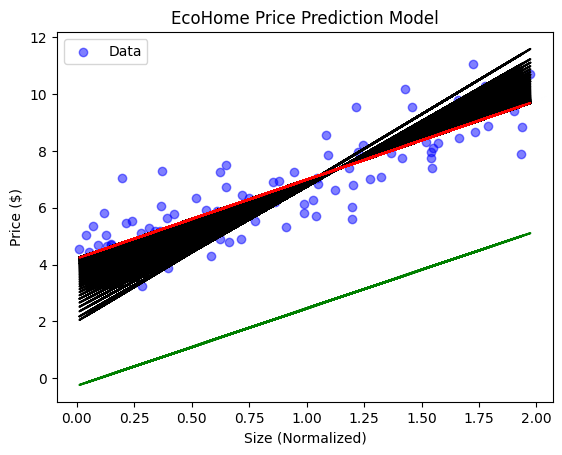

In [58]:
def gradient_descent_modified(X, y, learning_rate=0.1, n_iterations=1000):
    m = len(X)
    w = np.random.randn(2, 1) # Random initialization
    # print(m,w)
    plt.scatter(X_size, y, color='blue', alpha=0.5, label='Data')
    plt.plot(X_size, X_b.dot(w), color='green')
    for iteration in range(n_iterations):
        # TODO: Calculate Gradients
        gradients = (1 / m) * X.T @ (X @ w - y)
        # print(gradients)


        w = w - learning_rate * gradients
        # print(w)

        plt.plot(X_size, X_b.dot(w), color='black')
    plt.plot(X_size, X_b.dot(w), color='red')
    plt.legend()
    plt.title("EcoHome Price Prediction Model")
    plt.xlabel("Size (Normalized)")
    plt.ylabel("Price ($)")
    plt.show()
    return w

w_gd = gradient_descent_modified(X_b, y, learning_rate=0.5)

In [59]:
w_gd

array([[4.21509616],
       [2.77011339]])